In [5]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

In [2]:

ROOT = Path("..")
TEST = ROOT / "data/raw/test"
NAMES = ["glioma", "meningioma", "pituitary"]
model = YOLO(str(ROOT / "models/best.pt"))


def gt_from_label(path):
    """True class and bounding box (pixels) from a polygon label."""
    parts = path.read_text().split()
    xs = [float(v) * 640 for v in parts[1::2]]
    ys = [float(v) * 640 for v in parts[2::2]]
    return int(parts[0]), (min(xs), min(ys), max(xs), max(ys))


def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area = lambda r: (r[2] - r[0]) * (r[3] - r[1])
    return inter / (area(a) + area(b) - inter + 1e-9)

In [3]:
rows = []
for img in sorted((TEST / "images").glob("*.jpg")):
    true_cls, gt_box = gt_from_label(TEST / "labels" / f"{img.stem}.txt")
    res = model.predict(str(img), imgsz=640, conf=0.25, iou=0.5,
                        device="mps", verbose=False)[0]

    pred_cls, conf, overlap = None, 0.0, 0.0
    if len(res.boxes) == 0:
        outcome = "missed"
    else:
        top = res.boxes[res.boxes.conf.argmax()]
        pred_cls = int(top.cls[0])
        conf = float(top.conf[0])
        overlap = iou(top.xyxy[0].tolist(), gt_box)
        if pred_cls != true_cls:
            outcome = "wrong class"
        elif overlap < 0.5:
            outcome = "bad box"
        else:
            outcome = "correct"

    rows.append({
        "file": img.name,
        "true_cls": true_cls,
        "pred_cls": pred_cls,
        "conf": round(conf, 3),
        "iou": round(overlap, 3),
        "gt_area_pct": round((gt_box[2] - gt_box[0]) * (gt_box[3] - gt_box[1]) / 640**2 * 100, 2),
        "outcome": outcome,
    })

df = pd.DataFrame(rows)
df["true"] = df.true_cls.map(lambda i: NAMES[i])
df["pred"] = df.pred_cls.map(lambda i: NAMES[int(i)] if pd.notna(i) else "none")
print(len(df), "test images")

308 test images


In [4]:
print(pd.crosstab(df.true, df.outcome))
print()
print(pd.crosstab(df.true, df.pred))
print()
print(df.groupby(["true", "outcome"])["gt_area_pct"].median().unstack().round(2))

outcome     bad box  correct  missed  wrong class
true                                             
glioma           26      113      17            3
meningioma        2       59       1            0
pituitary         1       80       3            3

pred        glioma  meningioma  none  pituitary
true                                           
glioma         139           2    17          1
meningioma       0          61     1          0
pituitary        1           2     3         81

outcome     bad box  correct  missed  wrong class
true                                             
glioma         5.96     5.35    3.45         1.26
meningioma     8.48     4.36    2.79          NaN
pituitary      0.78     2.41    0.94         0.69


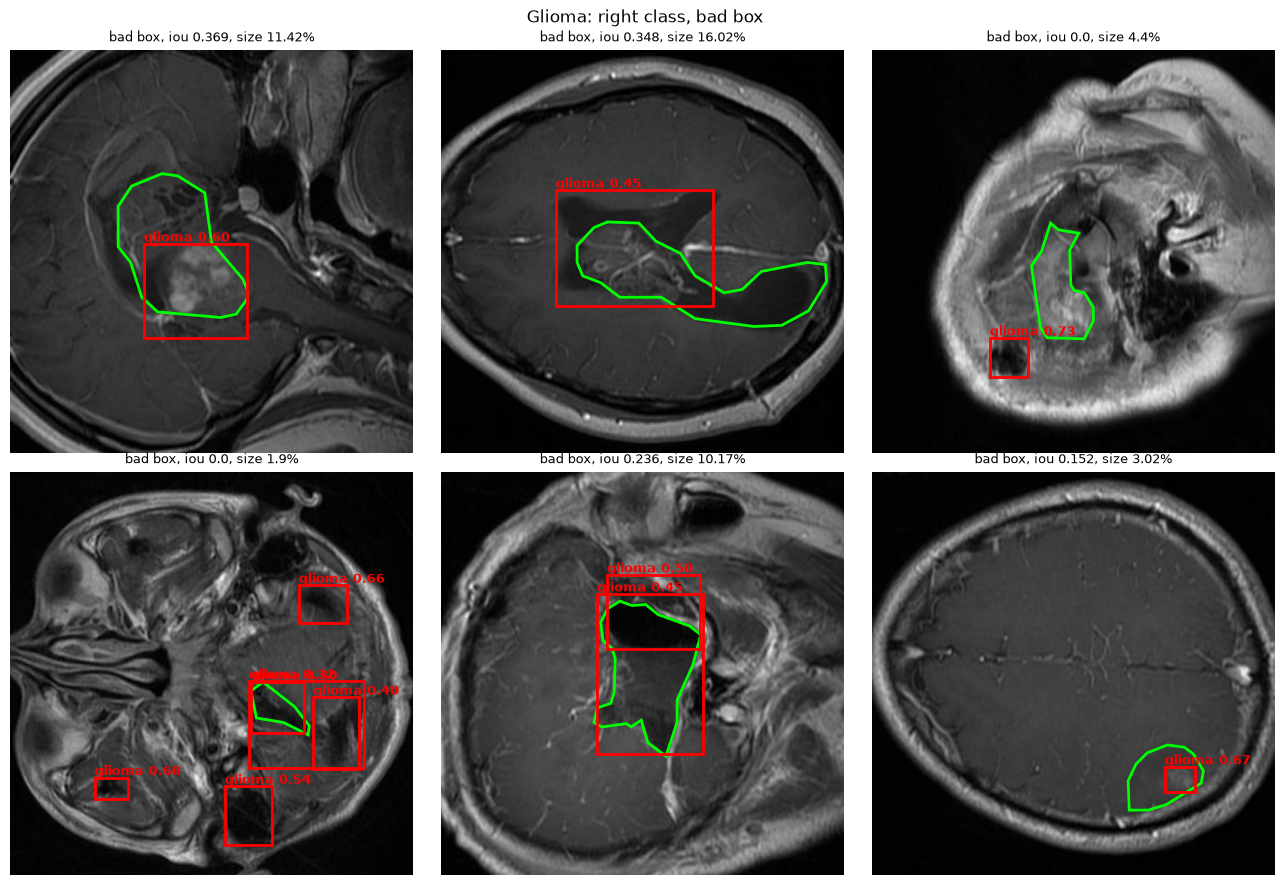

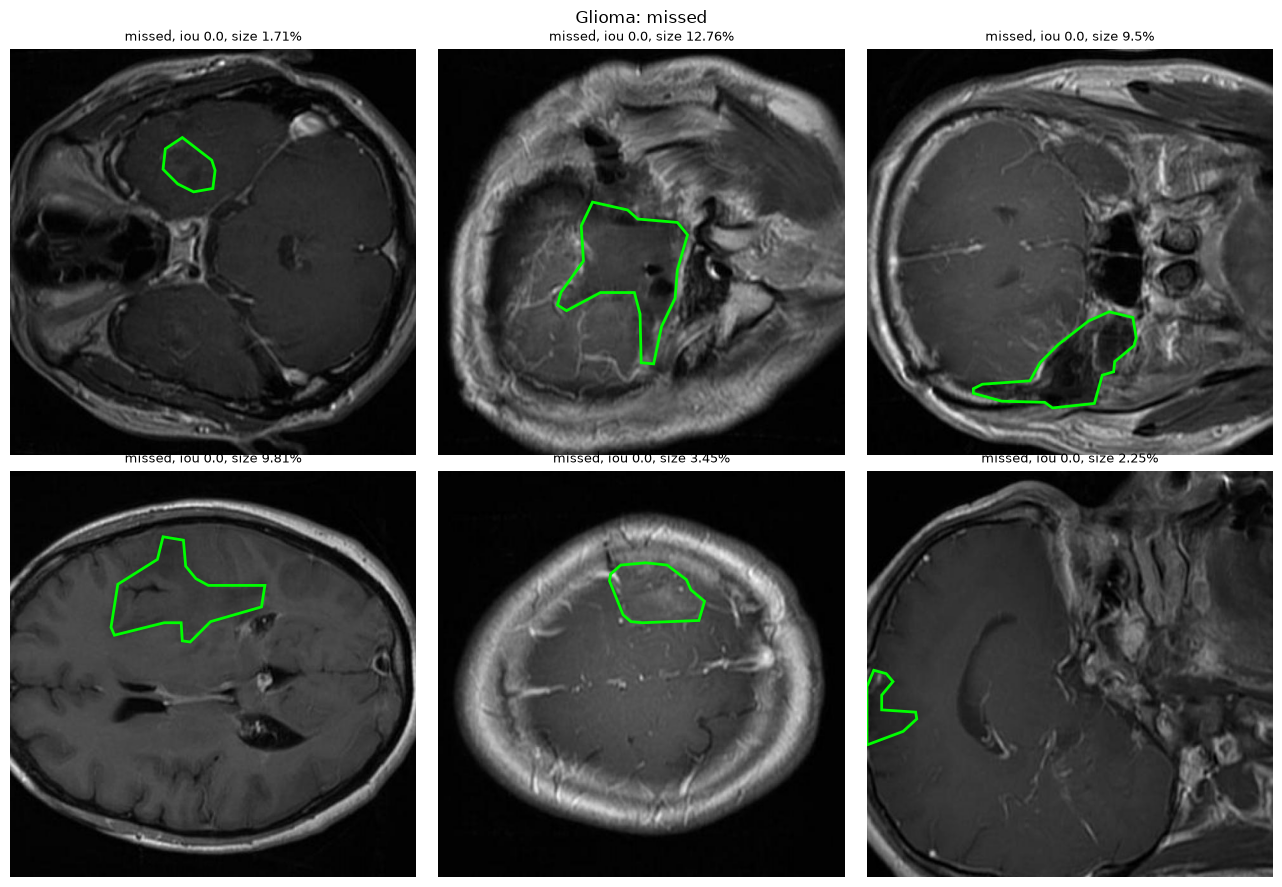

In [6]:
def show(subset, title):
    fig, axes = plt.subplots(2, 3, figsize=(13, 9))
    for ax, (_, r) in zip(axes.ravel(), subset.iterrows()):
        ax.imshow(Image.open(TEST / "images" / r.file), cmap="gray")

        parts = (TEST / "labels" / f"{Path(r.file).stem}.txt").read_text().split()
        pts = [(float(x) * 640, float(y) * 640) for x, y in zip(parts[1::2], parts[2::2])]
        ax.add_patch(patches.Polygon(pts, fill=False, edgecolor="lime", linewidth=2))

        res = model.predict(str(TEST / "images" / r.file), imgsz=640, conf=0.25,
                            iou=0.5, device="mps", verbose=False)[0]
        for b in res.boxes:
            x1, y1, x2, y2 = b.xyxy[0].tolist()
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                           edgecolor="red", linewidth=2))
            ax.text(x1, y1 - 4, f"{NAMES[int(b.cls[0])]} {float(b.conf[0]):.2f}",
                    color="red", fontsize=9, weight="bold")

        ax.set_title(f"{r.outcome}, iou {r.iou}, size {r.gt_area_pct}%", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


glioma = df[df.true == "glioma"]
show(glioma[glioma.outcome == "bad box"].sample(6, random_state=1), "Glioma: right class, bad box")
show(glioma[glioma.outcome == "missed"].sample(6, random_state=1), "Glioma: missed")

In [7]:
missed = df[(df.true == "glioma") & (df.outcome == "missed")]
rows = []
for _, r in missed.iterrows():
    _, gt_box = gt_from_label(TEST / "labels" / f"{Path(r.file).stem}.txt")
    res = model.predict(str(TEST / "images" / r.file), imgsz=640, conf=0.05,
                        iou=0.5, device="mps", verbose=False)[0]
    best_iou, best_conf = 0.0, 0.0
    for b in res.boxes:
        o = iou(b.xyxy[0].tolist(), gt_box)
        if o > best_iou:
            best_iou, best_conf = o, float(b.conf[0])
    rows.append({"file": r.file, "n_boxes": len(res.boxes),
                 "best_iou": round(best_iou, 2), "conf_of_best": round(best_conf, 2)})

print(pd.DataFrame(rows))
print("recovered (iou >= 0.5):", sum(x["best_iou"] >= 0.5 for x in rows), "of", len(rows))

                                                file  n_boxes  best_iou  \
0   1853_jpg.rf.22936007a95786a1540939608726b4d2.jpg        0      0.00   
1   1855_jpg.rf.f522b2d6e511f27e3c52681d177c306e.jpg        1      0.37   
2   1970_jpg.rf.8091ad01b620280c7171d511ce690e6e.jpg        1      0.00   
3   2098_jpg.rf.2739ad43fd1f67bec9c3040dca11e676.jpg        3      0.00   
4   2294_jpg.rf.fe5b37c011413bb3352e83fb2f4fb8e2.jpg        4      0.05   
5   2393_jpg.rf.cc4a702878cd4c69d84a37be11625197.jpg        2      0.72   
6   2402_jpg.rf.d98c0aff9256bbe19e23978ea0bad2b5.jpg        1      0.74   
7   2617_jpg.rf.62e2abf10342499048df0f87c99e3682.jpg        2      0.77   
8   2644_jpg.rf.a0fc4011f23db39f54925c2a1a997bfb.jpg        1      0.63   
9   2682_jpg.rf.55f36f4a88d75c8065b1ff8817665cce.jpg        2      0.00   
10  2748_jpg.rf.187db47b1d14080c2c986ae5f35ceae9.jpg        3      0.00   
11  2876_jpg.rf.d2b1fd2368dfd0f21f5c5ab288311247.jpg        4      0.24   
12  2914_jpg.rf.c1566b94c

## Glioma error analysis

On the 308 test images, the single best detection per image was compared with the true outline (correct means the right class and at least 50% box overlap).

| True class | Correct | Bad box | Missed | Wrong class |
|---|---|---|---|---|
| glioma (159) | 113 | 26 | 17 | 3 |
| meningioma (62) | 59 | 2 | 1 | 0 |
| pituitary (87) | 80 | 1 | 3 | 3 |

- Glioma is rarely confused with the other tumor types (3 of 159). Its weakness is localization and detection.
- The 26 bad boxes are mostly large, irregular outlines where the model boxes only part of the tumor, plus a few confident boxes on dark regions that are not the labelled tumor.
- Of the 17 missed gliomas, rerunning at a confidence threshold of 0.05 recovered 6 (box overlap 0.63 to 0.83), so those were detected with low confidence. 8 had only boxes elsewhere or partly on the tumor, and 3 had no detection at all.
- The images with no detection looked low-contrast to the eye, with little visible difference between the tumor and the tissue around it. This is a visual impression from a small sample, not a measured result.
- Lowering the confidence threshold could recover some misses, but its effect on false detections has not been measured.